## **Data preparation**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [3]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [4]:
df = pd.read_csv(data)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.to_csv('../data/churn.csv', index=False)

In [6]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [7]:
df.columns = df.columns.str.lower().str.replace(" ", "_").str.strip()

categorical_columns = list(df.dtypes[df.dtypes == "object"].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(" ", "_")

In [8]:
df.columns.to_list()

['customerid',
 'gender',
 'seniorcitizen',
 'partner',
 'dependents',
 'tenure',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod',
 'monthlycharges',
 'totalcharges',
 'churn']

In [9]:
tc = pd.to_numeric(df.totalcharges, errors = 'coerce')

In [10]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors = 'coerce')

In [11]:
df.totalcharges = df.totalcharges.fillna(0)

In [12]:
df['churn'] = (df['churn'] == 'yes').astype('int')

## **Setting up the validation framework**

In [13]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)

In [14]:
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

In [15]:
len(df_train), len(df_test)

(4225, 1409)

In [16]:
len(df_train), len(df_test), len(df_val)

(4225, 1409, 1409)

In [17]:
df_train = df_train.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)

In [18]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [19]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

## **EDA**

In [20]:
df_full_train = df_full_train.reset_index(drop = True)

In [21]:
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [22]:
global_churn_rate = round(df_full_train.churn.mean(), 2)
global_churn_rate

np.float64(0.27)

In [23]:
df_full_train

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
1,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
2,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
3,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
4,2364-ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,0781-lkxbr,male,1,no,no,9,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,100.50,918.60,1
5630,3507-gasnp,male,0,no,yes,60,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.95,1189.90,0
5631,8868-wozgu,male,0,no,no,28,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,105.70,2979.50,1
5632,1251-krreg,male,0,no,no,2,yes,yes,dsl,no,...,no,no,no,no,month-to-month,yes,mailed_check,54.40,114.10,1


In [24]:
df_full_train["churn"].value_counts()

churn
0    4113
1    1521
Name: count, dtype: int64

<Axes: xlabel='churn', ylabel='proportion'>

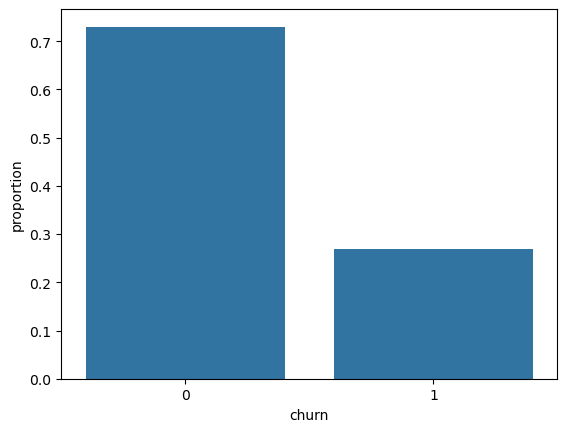

In [25]:
sns.barplot(df_full_train.churn.value_counts(normalize=True))

In [26]:
df_full_train.dtypes

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges        float64
churn                 int64
dtype: object

In [27]:
numerical = ['tenure', 'monthlycharges', 'totalcharges'] 

In [28]:
categorical = [ 
                'gender',
                'seniorcitizen',
                'partner',
                'dependents',
                'phoneservice',
                'multiplelines',
                'internetservice',
                'onlinesecurity',
                'onlinebackup',
                'deviceprotection',
                'techsupport',
                'streamingtv',
                'streamingmovies',
                'contract',
                'paperlessbilling',
                'paymentmethod'               
            ]

In [29]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

## **Feature importance: Churn rate and risk ratio**

In [30]:
df_full_train.pivot_table('churn', ['partner', 'dependents', 'gender'], 'contract', 'mean')

contract                   month-to-month  one_year  two_year
partner dependents gender                                    
no      no         female        0.484848  0.095041  0.052632
                   male          0.425926  0.126087  0.012500
        yes        female        0.323077  0.111111  0.052632
                   male          0.363636  0.073171  0.027778
yes     no         female        0.429032  0.133333  0.021164
                   male          0.465046  0.167832  0.044554
        yes        female        0.346457  0.115385  0.020761
                   male          0.341463  0.116751  0.021583

In [31]:
df_full_train.groupby('gender')['churn'].agg('mean')

gender
female    0.276824
male      0.263214
Name: churn, dtype: float64

In [32]:
df_full_train.groupby('partner')['churn'].agg('mean')

partner
no     0.329809
yes    0.205033
Name: churn, dtype: float64

In [33]:
churn_female = df_full_train[df_full_train['gender'] == 'female'].churn.mean()
churn_female

np.float64(0.27682403433476394)

In [34]:
churn_male = df_full_train[df_full_train['gender'] == 'male'].churn.mean()
churn_male

np.float64(0.2632135306553911)

In [35]:
global_churn_rate

np.float64(0.27)

In [36]:
churn_partner = df_full_train[df_full_train['partner'] == 'yes'].churn.mean()
churn_partner

np.float64(0.20503330866025166)

In [37]:
churn_no_partner = df_full_train[df_full_train['partner'] == 'no'].churn.mean()
churn_no_partner

np.float64(0.3298090040927694)

In [38]:
global_churn_rate - churn_partner

np.float64(0.06496669133974836)

In [39]:
global_churn_rate - churn_female

np.float64(-0.006824034334763918)

In [40]:
global_churn_rate - churn_male

np.float64(0.006786469344608914)

In [41]:
churn_partner / global_churn_rate

np.float64(0.7593826246675986)

In [42]:
churn_no_partner / global_churn_rate

np.float64(1.22151482997322)

In [43]:
from IPython.display import display

In [44]:
for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c)['churn'].agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn_rate
    df_group['risk'] = df_group['mean'] / global_churn_rate
    display(df_group)
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006824,1.025274
male,0.263214,2838,-0.006786,0.974865



seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027730,0.897297
1,0.413377,912,0.143377,1.531027



partner


,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059809,1.221515
yes,0.205033,2702,-0.064967,0.759383



dependents


,mean,count,diff,risk
dependents,,,,
no,0.313760,3968,0.043760,1.162074
yes,0.165666,1666,-0.104334,0.613579



phoneservice


,mean,count,diff,risk
phoneservice,,,,
no,0.241316,547,-0.028684,0.893764
yes,0.273049,5087,0.003049,1.011292



multiplelines


,mean,count,diff,risk
multiplelines,,,,
no,0.257407,2700,-0.012593,0.953361
no_phone_service,0.241316,547,-0.028684,0.893764
yes,0.290742,2387,0.020742,1.076820



internetservice


,mean,count,diff,risk
internetservice,,,,
dsl,0.192347,1934,-0.077653,0.712398
fiber_optic,0.425171,2479,0.155171,1.574709
no,0.077805,1221,-0.192195,0.288167



onlinesecurity


,mean,count,diff,risk
onlinesecurity,,,,
no,0.420921,2801,0.150921,1.558967
no_internet_service,0.077805,1221,-0.192195,0.288167
yes,0.153226,1612,-0.116774,0.567503



onlinebackup


,mean,count,diff,risk
onlinebackup,,,,
no,0.404323,2498,0.134323,1.497494
no_internet_service,0.077805,1221,-0.192195,0.288167
yes,0.217232,1915,-0.052768,0.804564



deviceprotection


,mean,count,diff,risk
deviceprotection,,,,
no,0.395875,2473,0.125875,1.466205
no_internet_service,0.077805,1221,-0.192195,0.288167
yes,0.230412,1940,-0.039588,0.853379



techsupport


,mean,count,diff,risk
techsupport,,,,
no,0.418914,2781,0.148914,1.551534
no_internet_service,0.077805,1221,-0.192195,0.288167
yes,0.159926,1632,-0.110074,0.592320



streamingtv


,mean,count,diff,risk
streamingtv,,,,
no,0.342832,2246,0.072832,1.269747
no_internet_service,0.077805,1221,-0.192195,0.288167
yes,0.302723,2167,0.032723,1.121195



streamingmovies


,mean,count,diff,risk
streamingmovies,,,,
no,0.338906,2213,0.068906,1.255209
no_internet_service,0.077805,1221,-0.192195,0.288167
yes,0.307273,2200,0.037273,1.138047



contract


,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161701,1.598893
one_year,0.120573,1186,-0.149427,0.446568
two_year,0.028274,1344,-0.241726,0.104718



paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097929,0.637300
yes,0.338151,3321,0.068151,1.252412



paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101829,0.622854
credit_card_(automatic),0.164339,1217,-0.105661,0.608661
electronic_check,0.455890,1893,0.185890,1.688482
mailed_check,0.193870,1305,-0.076130,0.718036


## **Feature importance:Mutual information**

In [45]:
from sklearn.metrics import mutual_info_score

In [46]:
mutual_score = {}
for c in categorical:
    
    mutual_info = mutual_info_score(df_full_train.churn, (df_full_train[c]))
    mutual_score[c] = mutual_info

sorted(mutual_score.items(), key = lambda x: x[1], reverse = True)


[('contract', 0.0983203874041556),
 ('onlinesecurity', 0.06308524972985574),
 ('techsupport', 0.06103245991777444),
 ('internetservice', 0.055867945893496467),
 ('onlinebackup', 0.0469234640537918),
 ('deviceprotection', 0.04345286925268559),
 ('paymentmethod', 0.043210027531582915),
 ('streamingtv', 0.03185333110086085),
 ('streamingmovies', 0.03158089669519908),
 ('paperlessbilling', 0.01758882715925275),
 ('dependents', 0.012345815445534689),
 ('partner', 0.009967689095399745),
 ('seniorcitizen', 0.009410216144208144),
 ('multiplelines', 0.0008574478744731856),
 ('phoneservice', 0.00022871269738296285),
 ('gender', 0.0001174846211139946)]

In [47]:
pd.DataFrame(
    mutual_score.items(), 
    columns = ['feature', 'mutual_info']).sort_values('mutual_info', ascending = False)

,feature,mutual_info
13,contract,0.098320
7,onlinesecurity,0.063085
10,techsupport,0.061032
6,internetservice,0.055868
8,onlinebackup,0.046923
9,deviceprotection,0.043453
15,paymentmethod,0.043210
11,streamingtv,0.031853
12,streamingmovies,0.031581
14,paperlessbilling,0.017589


## **Feature importance: Correlation**

In [48]:
numerical

['tenure', 'monthlycharges', 'totalcharges']

In [49]:
df_full_train.select_dtypes(include = 'number').corr()

,seniorcitizen,tenure,monthlycharges,totalcharges,churn
seniorcitizen,1.000000,0.023443,0.225234,0.110459,0.141966
tenure,0.023443,1.000000,0.251072,0.828268,-0.351885
monthlycharges,0.225234,0.251072,1.000000,0.650913,0.196805
totalcharges,0.110459,0.828268,0.650913,1.000000,-0.196353
churn,0.141966,-0.351885,0.196805,-0.196353,1.000000


In [50]:
df_full_train[numerical].corrwith(df_full_train['churn'])

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

In [51]:
df_full_train[df_full_train['tenure'] <= 2].churn.mean()

np.float64(0.5953420669577875)

In [52]:
df_full_train[(df_full_train['tenure'] > 2) & (df_full_train['tenure'] <= 12)].churn.mean()

np.float64(0.3994413407821229)

In [53]:
df_full_train[df_full_train['tenure'] > 12].churn.mean()

np.float64(0.17634908339788277)

In [54]:
df_full_train[df_full_train['monthlycharges'] <= 20].churn.mean()

np.float64(0.08795411089866156)

In [55]:
df_full_train[(df_full_train['monthlycharges'] > 20) & (df_full_train['monthlycharges'] <= 50)].churn.mean()

np.float64(0.18340943683409436)

In [56]:
df_full_train[df_full_train['monthlycharges'] > 50].churn.mean()

np.float64(0.32499341585462205)

## **One-hot encoding**

In [57]:
from sklearn.feature_extraction import DictVectorizer

In [58]:
train_dicts = df_train[categorical + numerical].to_dict(orient = 'records')

In [59]:
dv = DictVectorizer(sparse=False)

In [60]:
dv.fit(train_dicts)

,dtype,<class 'numpy.float64'>
,separator,'='
,sparse,False
,sort,True


In [61]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [62]:
X_train = dv.fit_transform(train_dicts)
X_train.shape

(4225, 45)

In [63]:
val_dicts = df_val[categorical + numerical].to_dict(orient = 'records')

In [64]:
X_val = dv.transform(val_dicts)
X_val.shape

(1409, 45)

## **Logistic regression**

In [65]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [66]:
z = np.linspace(-7, 7, 51)

In [67]:
sigmoid(z)

array([9.11051194e-04, 1.20508423e-03, 1.59386223e-03, 2.10780106e-03,
       2.78699622e-03, 3.68423990e-03, 4.86893124e-03, 6.43210847e-03,
       8.49286285e-03, 1.12064063e-02, 1.47740317e-02, 1.94550846e-02,
       2.55807883e-02, 3.35692233e-02, 4.39398154e-02, 5.73241759e-02,
       7.44679452e-02, 9.62155417e-02, 1.23467048e-01, 1.57095469e-01,
       1.97816111e-01, 2.46011284e-01, 3.01534784e-01, 3.63547460e-01,
       4.30453776e-01, 5.00000000e-01, 5.69546224e-01, 6.36452540e-01,
       6.98465216e-01, 7.53988716e-01, 8.02183889e-01, 8.42904531e-01,
       8.76532952e-01, 9.03784458e-01, 9.25532055e-01, 9.42675824e-01,
       9.56060185e-01, 9.66430777e-01, 9.74419212e-01, 9.80544915e-01,
       9.85225968e-01, 9.88793594e-01, 9.91507137e-01, 9.93567892e-01,
       9.95131069e-01, 9.96315760e-01, 9.97213004e-01, 9.97892199e-01,
       9.98406138e-01, 9.98794916e-01, 9.99088949e-01])

<Axes: >

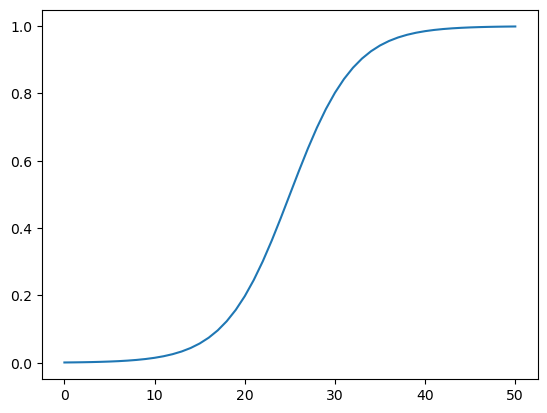

In [68]:
sns.lineplot(sigmoid(z))

In [69]:
def linear_regression(xi):
    result = w0

    for j in range(len(w)):
        result = result + xi[j] * w[j]
        
    return result

In [70]:
def logistic_regression(xi):
    score = w0

    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)   
    return result

## **Training logistic regression with Scikit Learn**

In [71]:
from sklearn.linear_model import LogisticRegression

In [72]:
model = LogisticRegression()
model.fit(X_train, y_train)

c:\Users\emman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [73]:
model.intercept_[0]

np.float64(-0.10902740157022876)

In [74]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [75]:
model.coef_[0].round(3)

array([ 0.475, -0.175, -0.408, -0.03 , -0.078,  0.063, -0.089, -0.081,
       -0.034, -0.073, -0.335,  0.317, -0.089,  0.004, -0.258,  0.141,
        0.009,  0.063, -0.089, -0.081,  0.266, -0.089, -0.284, -0.231,
        0.124, -0.166,  0.058, -0.087, -0.032,  0.07 , -0.059,  0.141,
       -0.249,  0.215, -0.12 , -0.089,  0.102, -0.071, -0.089,  0.052,
        0.213, -0.089, -0.232, -0.07 ,  0.   ])

In [76]:
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)

In [77]:
churn_decision

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [78]:
df_val[churn_decision].customerid

3       8433-wxgna
8       3440-jpscl
11      2637-fkfsy
12      7228-omtpn
19      6711-fldfb
           ...    
1397    5976-jcjrh
1398    2034-cgrhz
1399    5276-kqwhg
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 311, dtype: object

In [79]:
y_val, churn_decision

(array([0, 0, 0, ..., 0, 1, 1], shape=(1409,)),
 array([False, False, False, ..., False,  True,  True], shape=(1409,)))

In [80]:
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [81]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val

In [82]:
df_pred['correct'] = df_pred['actual'] == df_pred['prediction']

In [83]:
df_pred

,probability,prediction,actual,correct
0,0.008993,0,0,True
1,0.204550,0,0,True
2,0.212251,0,0,True
3,0.543059,1,1,True
4,0.213811,0,0,True
...,...,...,...,...
1404,0.313616,0,0,True
1405,0.039347,0,1,False
1406,0.136377,0,0,True
1407,0.799783,1,1,True


In [84]:
df_pred['correct'].mean()

np.float64(0.8034066713981547)

## **Model interpretation**

In [85]:
model.coef_[0].round(3)

array([ 0.475, -0.175, -0.408, -0.03 , -0.078,  0.063, -0.089, -0.081,
       -0.034, -0.073, -0.335,  0.317, -0.089,  0.004, -0.258,  0.141,
        0.009,  0.063, -0.089, -0.081,  0.266, -0.089, -0.284, -0.231,
        0.124, -0.166,  0.058, -0.087, -0.032,  0.07 , -0.059,  0.141,
       -0.249,  0.215, -0.12 , -0.089,  0.102, -0.071, -0.089,  0.052,
        0.213, -0.089, -0.232, -0.07 ,  0.   ])

In [86]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [87]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=month-to-month': np.float64(0.475),
 'contract=one_year': np.float64(-0.175),
 'contract=two_year': np.float64(-0.408),
 'dependents=no': np.float64(-0.03),
 'dependents=yes': np.float64(-0.078),
 'deviceprotection=no': np.float64(0.063),
 'deviceprotection=no_internet_service': np.float64(-0.089),
 'deviceprotection=yes': np.float64(-0.081),
 'gender=female': np.float64(-0.034),
 'gender=male': np.float64(-0.073),
 'internetservice=dsl': np.float64(-0.335),
 'internetservice=fiber_optic': np.float64(0.317),
 'internetservice=no': np.float64(-0.089),
 'monthlycharges': np.float64(0.004),
 'multiplelines=no': np.float64(-0.258),
 'multiplelines=no_phone_service': np.float64(0.141),
 'multiplelines=yes': np.float64(0.009),
 'onlinebackup=no': np.float64(0.063),
 'onlinebackup=no_internet_service': np.float64(-0.089),
 'onlinebackup=yes': np.float64(-0.081),
 'onlinesecurity=no': np.float64(0.266),
 'onlinesecurity=no_internet_service': np.float64(-0.089),
 'onlinesecurity=yes'

In [88]:
small = ['contract', 'tenure', 'monthlycharges']

In [89]:
df_train[small].iloc[:10].to_dict(orient = 'records')

[{'contract': 'two_year', 'tenure': 72, 'monthlycharges': 115.5},
 {'contract': 'month-to-month', 'tenure': 10, 'monthlycharges': 95.25},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 75.55},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 80.85},
 {'contract': 'two_year', 'tenure': 18, 'monthlycharges': 20.1},
 {'contract': 'month-to-month', 'tenure': 4, 'monthlycharges': 30.5},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 75.1},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 70.3},
 {'contract': 'two_year', 'tenure': 72, 'monthlycharges': 19.75},
 {'contract': 'month-to-month', 'tenure': 6, 'monthlycharges': 109.9}]

In [90]:
dicts_train_small = df_train[small].to_dict(orient = 'records')
dicts_val_small = df_val[small].to_dict(orient = 'records')

In [91]:
dv_small = DictVectorizer(sparse = False)
dv_small.fit(dicts_train_small)

,dtype,<class 'numpy.float64'>
,separator,'='
,sparse,False
,sort,True


In [92]:
dv_small.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'monthlycharges', 'tenure'], dtype=object)

In [93]:
X_train_small = dv_small.transform(dicts_train_small)

In [94]:
model_small = LogisticRegression()
model_small.fit(X_train_small, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [95]:
w0 = model_small.intercept_[0]
w0

np.float64(-2.477957595366708)

In [96]:
w = model_small.coef_[0]
w.round(3)

array([ 0.971, -0.024, -0.948,  0.027, -0.036])

In [97]:
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'contract=month-to-month': np.float64(0.971),
 'contract=one_year': np.float64(-0.024),
 'contract=two_year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

## **Using the model**

In [98]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient = 'records')
                                                                  

In [99]:
dv = DictVectorizer(sparse = False)
X_full_train  =dv.fit_transform(dicts_full_train)

In [100]:
y_full_train = df_full_train.churn.values

In [101]:
model = LogisticRegression()
model.fit(X_full_train, y_full_train)

c:\Users\emman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [102]:
dicts_test = df_test[categorical + numerical].to_dict(orient = 'records')


In [103]:
X_test = dv.transform(dicts_test)

In [104]:
y_pred = model.predict_proba(X_test)[:, 1]


In [105]:
y_pred

array([0.05549254, 0.13085302, 0.31821683, ..., 0.0063235 , 0.19544316,
       0.65895567], shape=(1409,))

In [106]:
y_val

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [126]:
churn_decision == (y_pred >= 0.5)

array([ True,  True,  True, ...,  True,  True,  True], shape=(1409,))

In [127]:
(churn_decision == y_test).mean()

np.float64(0.8147622427253371)

In [105]:
customer = dicts_test[10]
customer

{'gender': 'male',
 'seniorcitizen': 1,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'no',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'no',
 'onlinebackup': 'yes',
 'deviceprotection': 'no',
 'techsupport': 'no',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'mailed_check',
 'tenure': 32,
 'monthlycharges': 93.95,
 'totalcharges': 2861.45}

In [106]:
dv.transform(dicts_test[10])

array([[1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        0.00000e+00, 1.00000e+00, 0.00000e+00, 9.39500e+01, 1.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        0.00000e+00, 1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        1.00000e+00, 0.00000e+00, 1.00000e+00, 1.00000e+00, 0.00000e+00,
        0.00000e+00, 1.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        1.00000e+00, 0.00000e+00, 0.00000e+00, 3.20000e+01, 2.86145e+03]])

In [107]:
dv.transform([customer])

array([[1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        0.00000e+00, 1.00000e+00, 0.00000e+00, 9.39500e+01, 1.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        0.00000e+00, 1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        1.00000e+00, 0.00000e+00, 1.00000e+00, 1.00000e+00, 0.00000e+00,
        0.00000e+00, 1.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        1.00000e+00, 0.00000e+00, 0.00000e+00, 3.20000e+01, 2.86145e+03]])

In [108]:
model.predict_proba(dv.transform([customer]))

array([[0.50164888, 0.49835112]])

In [109]:
model.predict_proba(dv.transform(dicts_test[-1]))

array([[0.34104433, 0.65895567]])

## **Evaluation Metrics**

## **Accuracy and Dummy model**

In [151]:
len(y_val)

1409

In [152]:
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [8]:
np.linspace(0, 1, 100).round(2)

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.51, 0.52, 0.53, 0.54, 0.55,
       0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65, 0.66,
       0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77,
       0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87, 0.88,
       0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99,
       1.  ])

In [154]:
threshold = np.linspace(0, 1, 21)

scores = []

for t in threshold:
    churn_decision = (y_pred >= t)
    score = (y_val == churn_decision).mean()
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.509
0.10 0.591
0.15 0.666
0.20 0.710
0.25 0.739
0.30 0.760
0.35 0.772
0.40 0.785
0.45 0.793
0.50 0.803
0.55 0.801
0.60 0.795
0.65 0.786
0.70 0.766
0.75 0.744
0.80 0.735
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


In [160]:
from sklearn.metrics import accuracy_score

In [163]:
accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

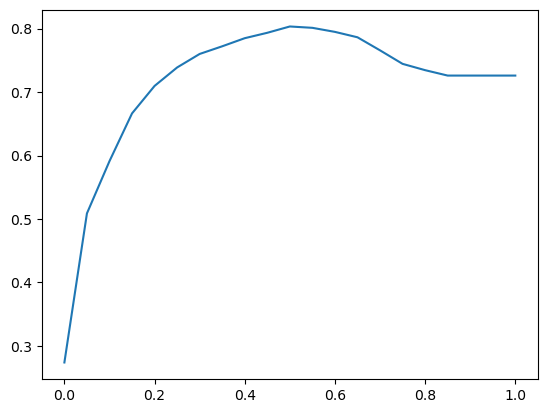

In [162]:
plt.plot(threshold, scores)

In [165]:
1 - y_val.mean(

)

np.float64(0.7260468417317246)

## **Comfusion tables**

In [177]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

In [178]:
t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [184]:
predict_negative

array([ True,  True,  True, ...,  True, False, False], shape=(1409,))

In [182]:
predict_positive

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [189]:
tp = (actual_positive & predict_positive).sum()
tn = (actual_negative & predict_negative).sum()

In [190]:
tp, tn

(np.int64(210), np.int64(922))

In [191]:
fp = (actual_negative & predict_positive).sum()
fn = (actual_positive & predict_negative).sum()

In [192]:
fp, fn

(np.int64(101), np.int64(176))

In [193]:
tp + tn + fp +fn

np.int64(1409)

In [195]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[922, 101],
       [176, 210]])

## **Precision and Recall**

In [200]:
(tp + tn) / (tp + tn + fp +fn )

np.float64(0.8034066713981547)

In [199]:
p = tp / (tp + fp)
p

np.float64(0.6752411575562701)

In [201]:
tp

np.int64(210)

In [202]:
fp

np.int64(101)

In [207]:
r = tp / (tp + fn)
r

np.float64(0.5440414507772021)

## **ROC Curves**

In [208]:
tpr = tp / (tp + fn)
tpr

np.float64(0.5440414507772021)

In [209]:
fpr = fp / (fp + tn)
fpr

np.float64(0.09872922776148582)

In [219]:
score = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (actual_positive & predict_positive).sum()
    tn = (actual_negative & predict_negative).sum()

    fp = (actual_negative & predict_positive).sum()
    fn = (actual_positive & predict_negative).sum()

    score.append((t, tp, fp, fn, tn))

In [220]:
score

[(np.float64(0.0), np.int64(386), np.int64(1023), np.int64(0), np.int64(0)),
 (np.float64(0.01), np.int64(385), np.int64(913), np.int64(1), np.int64(110)),
 (np.float64(0.02), np.int64(384), np.int64(830), np.int64(2), np.int64(193)),
 (np.float64(0.03), np.int64(383), np.int64(766), np.int64(3), np.int64(257)),
 (np.float64(0.04), np.int64(381), np.int64(715), np.int64(5), np.int64(308)),
 (np.float64(0.05), np.int64(379), np.int64(685), np.int64(7), np.int64(338)),
 (np.float64(0.06), np.int64(377), np.int64(661), np.int64(9), np.int64(362)),
 (np.float64(0.07), np.int64(372), np.int64(641), np.int64(14), np.int64(382)),
 (np.float64(0.08), np.int64(371), np.int64(613), np.int64(15), np.int64(410)),
 (np.float64(0.09), np.int64(369), np.int64(580), np.int64(17), np.int64(443)),
 (np.float64(0.1), np.int64(366), np.int64(556), np.int64(20), np.int64(467)),
 (np.float64(0.11), np.int64(365), np.int64(528), np.int64(21), np.int64(495)),
 (np.float64(0.12), np.int64(365), np.int64(509), 

In [224]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_score = pd.DataFrame(score, columns = columns)
df_score

,threshold,tp,fp,fn,tn
0,0.00,386,1023,0,0
1,0.01,385,913,1,110
2,0.02,384,830,2,193
3,0.03,383,766,3,257
4,0.04,381,715,5,308
...,...,...,...,...,...
96,0.96,0,0,386,1023
97,0.97,0,0,386,1023
98,0.98,0,0,386,1023
99,0.99,0,0,386,1023


In [229]:
df_score['tpr'] = (df_score.tp) / (df_score.tp + df_score.fn)
df_score['fpr'] = (df_score.fp) / (df_score.fp + df_score.tn)

In [230]:
df_score[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,366,556,20,467,0.948187,0.543500
20,0.2,333,356,53,667,0.862694,0.347996
30,0.3,284,236,102,787,0.735751,0.230694
40,0.4,249,166,137,857,0.645078,0.162268
50,0.5,210,101,176,922,0.544041,0.098729
60,0.6,150,53,236,970,0.388601,0.051808
70,0.7,76,20,310,1003,0.196891,0.019550
80,0.8,13,1,373,1022,0.033679,0.000978
90,0.9,0,0,386,1023,0.000000,0.000000


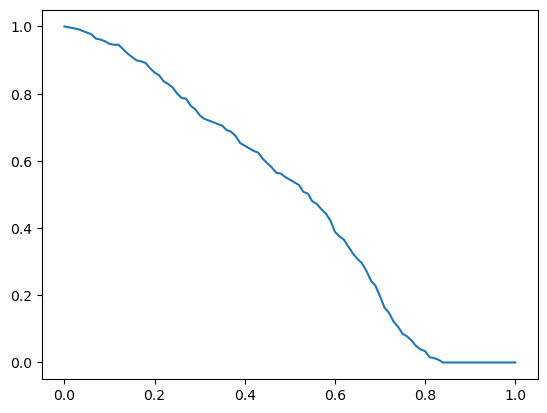

In [243]:
plt.plot(df_score.threshold, df_score.tpr)

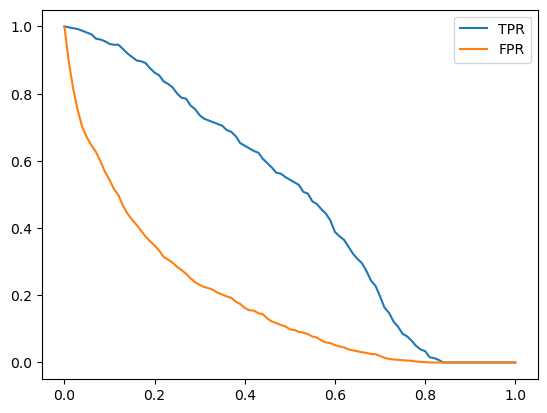

In [244]:
plt.plot(df_score.threshold, df_score.tpr, label = 'TPR')
plt.plot(df_score.threshold, df_score.fpr, label = 'FPR')
plt.legend()

## **Random model**

In [245]:
np.random.seed(1)

y_rand = np.random.uniform(0, 1, size = len(y_val))

In [247]:
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

In [249]:
def tpr_fpr_dataframe(y_val, y_pred):
    score = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (actual_positive & predict_positive).sum()
        tn = (actual_negative & predict_negative).sum()

        fp = (actual_negative & predict_positive).sum()
        fn = (actual_positive & predict_negative).sum()

        score.append((t, tp, fp, fn, tn))
    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_score = pd.DataFrame(score, columns = columns)

    df_score['tpr'] = (df_score.tp) / (df_score.tp + df_score.fn)
    df_score['fpr'] = (df_score.fp) / (df_score.fp + df_score.tn)

    return df_score

In [251]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

In [252]:
df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


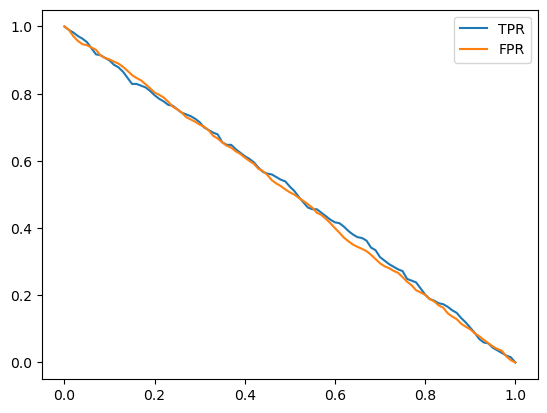

In [253]:
plt.plot(df_score.threshold, df_rand.tpr, label = 'TPR')
plt.plot(df_score.threshold, df_rand.fpr, label = 'FPR')
plt.legend()

## **Ideal model**

In [254]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [256]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [257]:
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [258]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [259]:
((y_ideal_pred >= 0.726) == y_ideal).mean()

np.float64(1.0)

In [260]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

In [261]:
df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


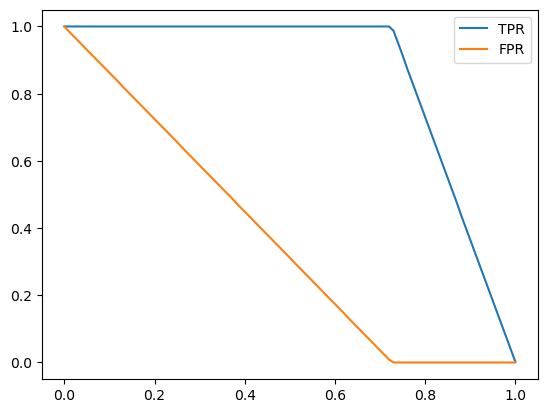

In [262]:
plt.plot(df_score.threshold, df_ideal.tpr, label = 'TPR')
plt.plot(df_score.threshold, df_ideal.fpr, label = 'FPR')
plt.legend()

## **Putting everything together**

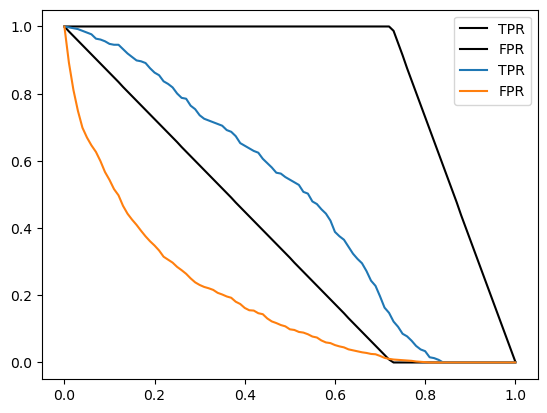

In [264]:
plt.plot(df_score.threshold, df_ideal.tpr, label = 'TPR', color = 'black')
plt.plot(df_score.threshold, df_ideal.fpr, label = 'FPR', color = 'black')

# plt.plot(df_score.threshold, df_rand.tpr, label = 'TPR')
# plt.plot(df_score.threshold, df_rand.fpr, label = 'FPR')

plt.plot(df_score.threshold, df_score.tpr, label = 'TPR')
plt.plot(df_score.threshold, df_score.fpr, label = 'FPR')

plt.legend()

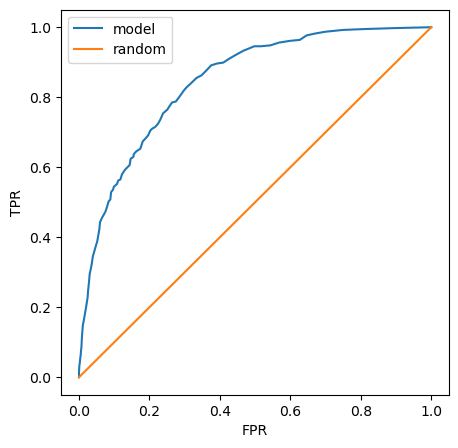

In [274]:
plt.figure(figsize = (5, 5))

# plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal', color = 'black')
plt.plot(df_score.fpr, df_score.tpr, label = 'model')
plt.plot([0, 1], [0, 1], label = 'random')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [275]:
from sklearn.metrics import roc_curve

In [276]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

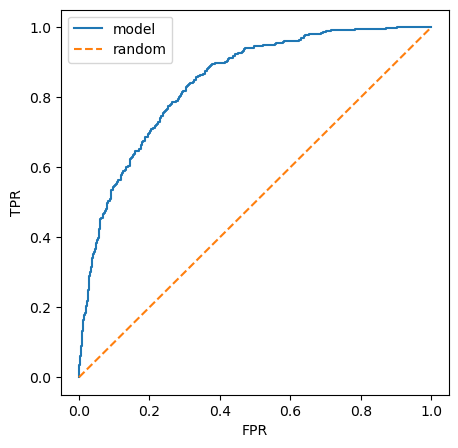

In [285]:
plt.figure(figsize = (5, 5))

# plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal', color = 'black')
plt.plot(fpr, tpr, label = 'model')
plt.plot([0, 1], [0, 1], label = 'random', linestyle = '--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

## **ROC AUC**

In [287]:
from sklearn.metrics import auc

In [288]:
auc(fpr, tpr)

0.8438530381535563

In [289]:
auc(df_score.fpr, df_score.tpr)

0.8438732975754537

In [290]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [294]:
from sklearn.metrics import roc_auc_score

In [295]:
roc_auc_score(y_val, y_pred)

0.8438530381535563

In [300]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

In [309]:
import random

In [310]:
n = 100000

success = 0

for i in range(n):
    pos_idx = random.randint(0, len(pos) - 1)
    neg_idx = random.randint(0, len(neg) - 1)

    if pos[pos_idx] > neg[neg_idx]:
        success += 1

success / n

0.84359

In [311]:
n = 50000

np.random.seed(1)
pos_idn = np.random.randint(0, len(pos), size = n)
neg_idn = np.random.randint(0, len(neg), size = n)

(pos[pos_idn] > neg[neg_idn]).mean()

np.float64(0.84648)

## **Cross-Validation**

In [348]:
def train(df, y, C = 1):
    dicts = df[categorical + numerical].to_dict(orient = 'records')

    dv = DictVectorizer(sparse = False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C = C, max_iter = 100000)
    model.fit(X_train, y)

    return dv, model

In [349]:
dv, model = train(df_train, y_train)

In [350]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient = 'records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [351]:
y_pred = predict(df_val, dv, model)

In [333]:
from sklearn.model_selection import KFold

In [352]:
kfold = KFold(n_splits = 10, shuffle = True, random_state = 1)

In [353]:
train_idx, val_idx = next(kfold.split(df_full_train))

In [354]:
len(train_idx), len(val_idx)

(5070, 564)

In [355]:
import tqdm

In [356]:
n_splits = 5
for C in tqdm.tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits = n_splits, shuffle = True, random_state = 1)

    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):

        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C = C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

 14%|█▍        | 1/7 [00:05<00:33,  5.63s/it]

C=0.001 0.825 +- 0.009


 29%|██▊       | 2/7 [00:14<00:39,  7.82s/it]

C=0.01 0.840 +- 0.008


 43%|████▎     | 3/7 [00:38<01:00, 15.01s/it]

C=0.1 0.842 +- 0.007


 57%|█████▋    | 4/7 [00:51<00:43, 14.39s/it]

C=0.5 0.842 +- 0.007


 71%|███████▏  | 5/7 [01:01<00:25, 12.52s/it]

C=1 0.842 +- 0.007


 86%|████████▌ | 6/7 [01:13<00:12, 12.41s/it]

C=5 0.842 +- 0.007


100%|██████████| 7/7 [01:27<00:00, 12.56s/it]

C=10 0.842 +- 0.007


In [347]:
len(df_test)

1409

In [358]:
dv, model = train(df_full_train, df_full_train.churn.values, C = 1)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8584438341620895

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        5634 non-null   object 
 1   gender            5634 non-null   object 
 2   seniorcitizen     5634 non-null   int64  
 3   partner           5634 non-null   object 
 4   dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   phoneservice      5634 non-null   object 
 7   multiplelines     5634 non-null   object 
 8   internetservice   5634 non-null   object 
 9   onlinesecurity    5634 non-null   object 
 10  onlinebackup      5634 non-null   object 
 11  deviceprotection  5634 non-null   object 
 12  techsupport       5634 non-null   object 
 13  streamingtv       5634 non-null   object 
 14  streamingmovies   5634 non-null   object 
 15  contract          5634 non-null   object 
 16  paperlessbilling  5634 non-null   object 
